# Stage 8 -- Monitoring and drift (PSI / CSI)

We monitor two things:

- **Score drift**: PSI of the model output (risk score) between a reference
  and a current population.
- **Input drift (CSI)**: PSI per feature.

Home Credit has only relative day offsets, so there is no true out-of-time
window. We use the training partition as the reference and the holdout as
the current population for the stable baseline, then simulate a shifted
population to show the index reacting. Reusable logic lives in
`src/monitor.py`; the runnable report is `python -m src.monitor`.

Bands: stable < 0.10, watch 0.10-0.25, alert >= 0.25.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.modeling import load_model, load_modeling_data
from src.monitor import (
    population_stability_index,
    feature_psi,
    score_psi,
    drift_status,
)

plt.rcParams['figure.dpi'] = 110

## Load champion, reference (train), and current (holdout)

In [2]:
model = load_model('champion')
data = load_modeling_data()
ref_X, cur_X = data.X_train, data.X_holdout
print('reference:', ref_X.shape, 'current:', cur_X.shape)

reference: (246005, 52) current: (61502, 52)


## Baseline: train vs holdout should be stable

In [3]:
s_psi = score_psi(model, ref_X, cur_X)
print(f'score PSI = {s_psi:.5f} ({drift_status(s_psi)})')

csi = feature_psi(ref_X, cur_X, data.feature_cols)
print(csi['status'].value_counts().to_dict())
csi.head(10)

score PSI = 0.00033 (stable)


{'stable': 52}


,feature,psi,status
0,bur_utilisation,0.000626,stable
1,cc_drawings_mean,0.000533,stable
2,cc_utilisation_mean,0.000415,stable
3,app_ext_source_2,0.000369,stable
4,cc_balance_trend,0.000361,stable
5,app_amt_credit,0.000322,stable
6,app_ext_source_1,0.000315,stable
7,app_age_years,0.000301,stable
8,prev_credit_to_application_mean,0.000294,stable
9,prev_amt_application_mean,0.000293,stable


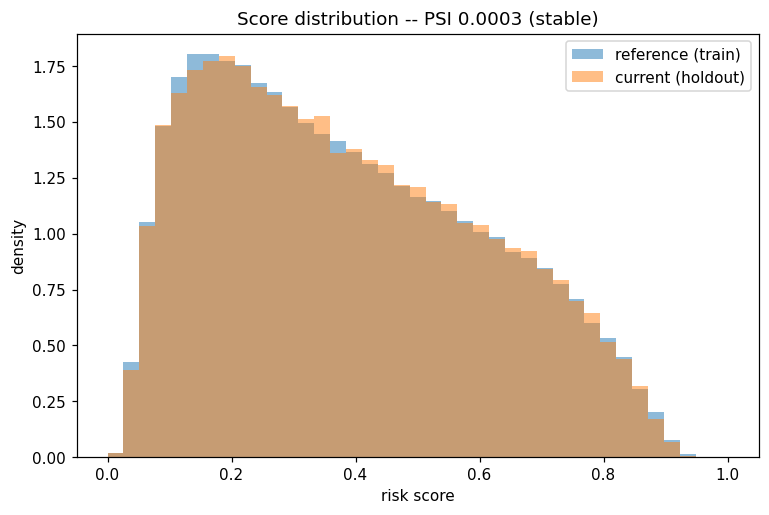

In [4]:
ref_score = model.predict_proba(ref_X)[:, 1]
cur_score = model.predict_proba(cur_X)[:, 1]
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.linspace(0, 1, 40)
ax.hist(ref_score, bins=bins, density=True, alpha=0.5, label='reference (train)')
ax.hist(cur_score, bins=bins, density=True, alpha=0.5, label='current (holdout)')
ax.set_xlabel('risk score')
ax.set_ylabel('density')
ax.set_title(f'Score distribution -- PSI {s_psi:.4f} ({drift_status(s_psi)})')
ax.legend()
plt.show()

## Simulated drift

We shift the holdout to mimic a worsening population: lower external credit
scores, higher leverage, and more recent-installment lateness. This is a
what-if stress test, not real data.

In [5]:
rng = np.random.default_rng(42)
drifted = cur_X.copy()
for col in ['app_ext_source_1', 'app_ext_source_2', 'app_ext_source_3']:
    drifted[col] = (drifted[col] - 0.15).clip(lower=0.0)
drifted['app_credit_to_income'] = drifted['app_credit_to_income'] * 1.4
for col in ['inst_late_rate', 'inst_late_rate_3m', 'inst_late_rate_6m',
            'inst_late_rate_12m']:
    if col in drifted:
        drifted[col] = (drifted[col] + 0.1).clip(upper=1.0)

s_psi_d = score_psi(model, ref_X, drifted)
print(f'drifted score PSI = {s_psi_d:.5f} ({drift_status(s_psi_d)})')
csi_d = feature_psi(ref_X, drifted, data.feature_cols)
print(csi_d['status'].value_counts().to_dict())
csi_d.head(10)

drifted score PSI = 0.92796 (alert)


{'stable': 45, 'alert': 6, 'watch': 1}


,feature,psi,status
0,inst_late_rate_6m,12.408582,alert
1,inst_late_rate_12m,12.286693,alert
2,inst_late_rate,9.899506,alert
3,app_ext_source_2,2.580304,alert
4,app_ext_source_3,1.712667,alert
5,app_ext_source_1,0.915513,alert
6,app_credit_to_income,0.238479,watch
7,inst_late_rate_3m,0.007052,stable
8,bur_utilisation,0.000626,stable
9,cc_drawings_mean,0.000533,stable


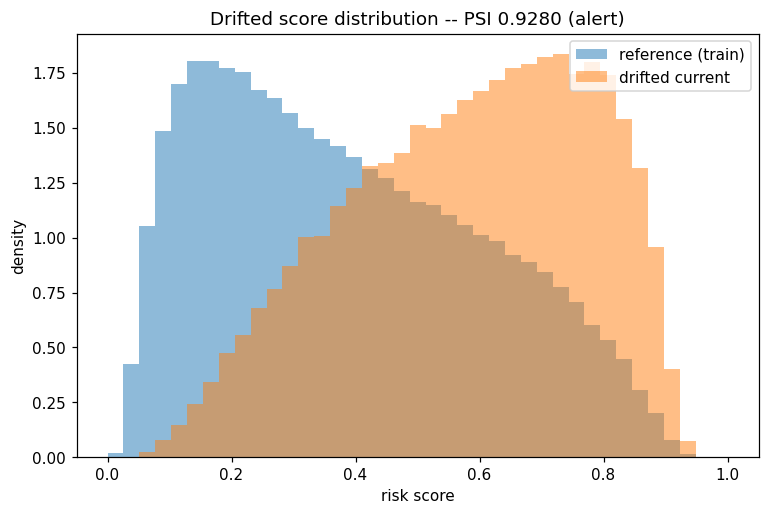

In [6]:
drift_score = model.predict_proba(drifted)[:, 1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(ref_score, bins=bins, density=True, alpha=0.5, label='reference (train)')
ax.hist(drift_score, bins=bins, density=True, alpha=0.5, label='drifted current')
ax.set_xlabel('risk score')
ax.set_ylabel('density')
ax.set_title(f'Drifted score distribution -- PSI {s_psi_d:.4f}'
             f' ({drift_status(s_psi_d)})')
ax.legend()
plt.show()

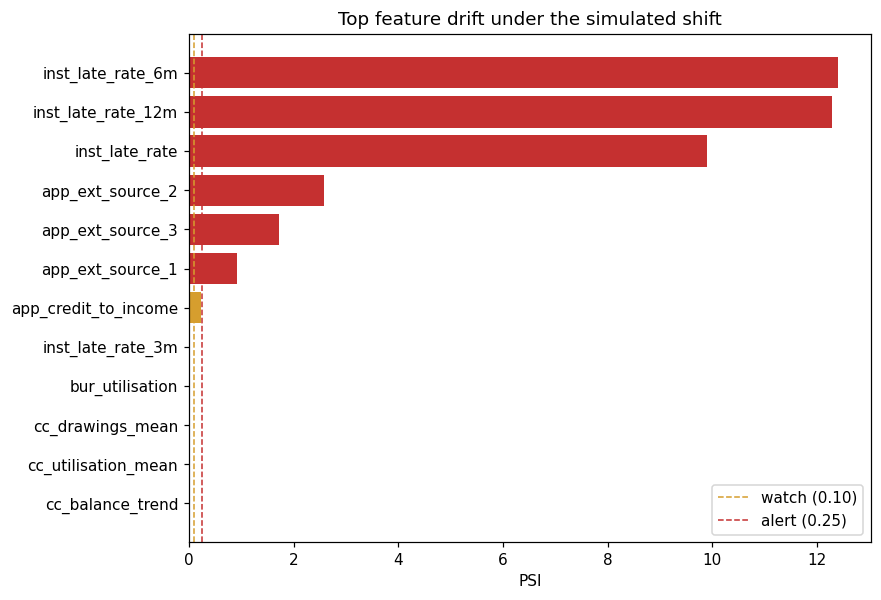

In [7]:
top = csi_d.head(12).iloc[::-1]
colors = {'stable': '#2f855a', 'watch': '#d69e2e', 'alert': '#c53030'}
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top['feature'], top['psi'], color=[colors[s] for s in top['status']])
ax.axvline(0.10, color='#d69e2e', ls='--', lw=1, label='watch (0.10)')
ax.axvline(0.25, color='#c53030', ls='--', lw=1, label='alert (0.25)')
ax.set_xlabel('PSI')
ax.set_title('Top feature drift under the simulated shift')
ax.legend()
plt.show()

## Takeaways

- Train vs holdout is stable (PSI well under 0.10 for the score and every
  feature), confirming the holdout matches the training population.
- The simulated shift pushes the shifted features and the model score into
  the watch/alert bands, demonstrating the monitor reacts as intended.
- In production this job runs on each new scoring batch; `python -m
  src.monitor` writes `reports/drift_report.md` and `reports/drift.json`.